## Imports

In [10]:
import cv2
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from ultralytics import YOLO

## Load Trained Model

In [11]:
plate_detector = YOLO(
    "../models/license_plate_detector.pt"
)
character_detector = YOLO(
    "../models/license_plate_character_detector.pt"
)
cnn_model = keras.models.load_model(
    "../models/license_plate_character_cnn.keras"
)

## Load Class Mapping

In [12]:
with open("../models/class_mapping.json", "r", encoding="utf-8") as f:
    index_to_class = json.load(f)

index_to_class = {
    int(index): label
    for index, label in index_to_class.items()
}

## Load New Plate Image

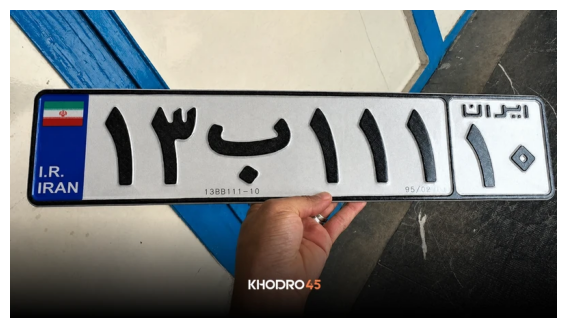

(451, 800, 3)


In [13]:
image_path = "../data/sample_plate.jpg"

# for showing the image
plate_image = cv2.imread(image_path)

plt.figure(figsize=(12, 4))
plt.imshow(
    cv2.cvtColor(plate_image, cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()

print(plate_image.shape)

## Build Full Vehicle License Plate Recognition Pipeline

In [14]:
def recognize_plate_from_vehicle(
    image_path,
    plate_conf=0.1,
    character_conf=0.5
):
    # Load full vehicle image
    vehicle_image = cv2.imread(image_path)

    if vehicle_image is None:
        raise ValueError("Could not load vehicle image.")

    # ---------------------------------
    # 1. Detect license plate
    # ---------------------------------

    plate_results = plate_detector.predict(
        source=image_path,
        conf=plate_conf,
        verbose=False
    )

    plate_result = plate_results[0]

    if len(plate_result.boxes) == 0:
        return None

    # Choose the plate detection
    # with the highest confidence
    plate_confidences = (
        plate_result.boxes.conf.cpu().numpy()
    )

    best_plate_index = np.argmax(
        plate_confidences
    )

    plate_box = (
        plate_result.boxes.xyxy
        .cpu()
        .numpy()[best_plate_index]
    )

    xmin, ymin, xmax, ymax = map(
        int,
        plate_box
    )

    # ---------------------------------
    # 2. Crop license plate
    # ---------------------------------

    plate_crop = vehicle_image[
        ymin:ymax,
        xmin:xmax
    ]

    # ---------------------------------
    # 3. Detect characters
    # ---------------------------------

    character_results = character_detector.predict(
        source=plate_crop,
        conf=character_conf,
        verbose=False
    )

    character_result = character_results[0]

    if len(character_result.boxes) == 0:
        return None

    character_boxes = (
        character_result.boxes.xyxy
        .cpu()
        .numpy()
    )

    # ---------------------------------
    # 4. Sort characters left to right
    # ---------------------------------

    character_boxes = sorted(
        character_boxes,
        key=lambda box: box[0]
    )

    # ---------------------------------
    # 5. Crop characters
    # ---------------------------------

    cropped_characters = []

    for box in character_boxes:
        char_xmin, char_ymin, char_xmax, char_ymax = map(
            int,
            box
        )

        character_crop = plate_crop[
            char_ymin:char_ymax,
            char_xmin:char_xmax
        ]

        cropped_characters.append(
            character_crop
        )

    # ---------------------------------
    # 6. Preprocess for CNN
    # ---------------------------------

    processed_characters = []

    for character in cropped_characters:

        resized_character = cv2.resize(
            character,
            (32, 64)
        )

        gray_character = cv2.cvtColor(
            resized_character,
            cv2.COLOR_BGR2GRAY
        )

        normalized_character = (
            gray_character.astype("float32")
            / 255.0
        )

        normalized_character = np.expand_dims(
            normalized_character,
            axis=-1
        )

        processed_characters.append(
            normalized_character
        )

    X_characters = np.array(
        processed_characters
    )

    # ---------------------------------
    # 7. Predict character classes
    # ---------------------------------

    predictions = cnn_model.predict(
        X_characters,
        verbose=0
    )

    predicted_indices = np.argmax(
        predictions,
        axis=1
    )

    predicted_labels = [
        index_to_class[index]
        for index in predicted_indices
    ]

    # ---------------------------------
    # 8. Build final plate text
    # ---------------------------------

    plate_text = "\u200e".join(
        predicted_labels
    )

    # ---------------------------------
    # Return useful results
    # ---------------------------------

    return {
        "plate_text": plate_text,
        "labels": predicted_labels,
        "plate_crop": plate_crop,
        "plate_confidence": float(
            plate_confidences[
                best_plate_index
            ]
        )
    }

In [22]:
image_path = "../data/plate_test/day_15407.jpg"

plate = recognize_plate_from_vehicle(image_path)
result = plate["plate_text"]

print("Predicted Plate:", result)

Predicted Plate: 2‎9‎م‎8‎1‎8‎1‎0
